In [1]:
dev_by = "अनुज शर्मा"
checked_by = "वैशाली इंगळे"

print("Made by: " + dev_by + "\n" + "Submitted to: " + checked_by)

Made by: अनुज शर्मा
Submitted to: वैशाली इंगळे


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import seaborn as sns

# Loading Dataset

In [3]:
df = pd.read_csv("Student Social Media And Mental Health Impact1.csv")

In [4]:
df.shape

(5000, 13)

In [5]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


# Data Cleaning

In [6]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,4997.000000,4998.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.009326,1.750960,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637068,0.668492,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [7]:
df.duplicated().sum()

np.int64(2)

In [1]:
df = df.drop_duplicates()


NameError: name 'df' is not defined

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)


# Missing Value Handling

In [11]:
df.isnull().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,5
Purpose_Of_Use,5
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,3
Physical_Activity_Hours,2


In [12]:
df['Most_Used_Platform'] = df['Most_Used_Platform'].fillna(df['Most_Used_Platform'].mode()[0])
df['Purpose_Of_Use'] = df['Purpose_Of_Use'].fillna(df['Purpose_Of_Use'].mode()[0])

df['Study_Hours'] = df['Study_Hours'].fillna(df['Study_Hours'].median())
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].fillna(df['Physical_Activity_Hours'].median())


In [13]:
df.isnull().sum()

,0
Age,0
Gender,0
Country,0
Academic_Level,0
Most_Used_Platform,0
Purpose_Of_Use,0
Avg_Daily_Usage_Hours,0
Daily_Unlocks,0
Study_Hours,0
Physical_Activity_Hours,0


# Statistical analysis

In [14]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.009184,1.751100,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636399,0.667243,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,0.000000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


<Axes: >

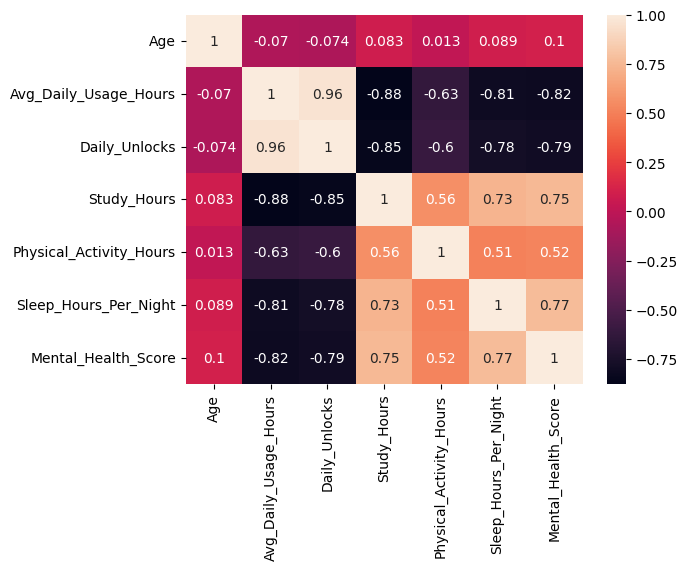

In [15]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

# Data visualization using histograms and boxplots

In [16]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

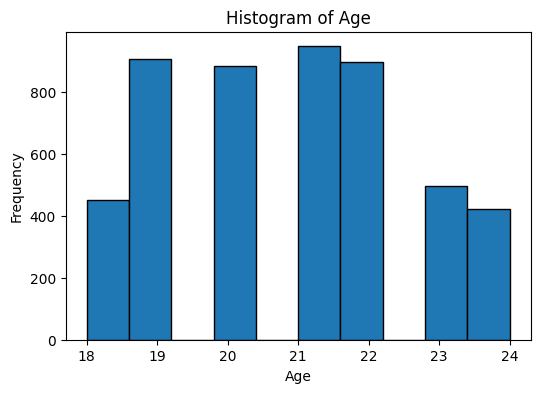

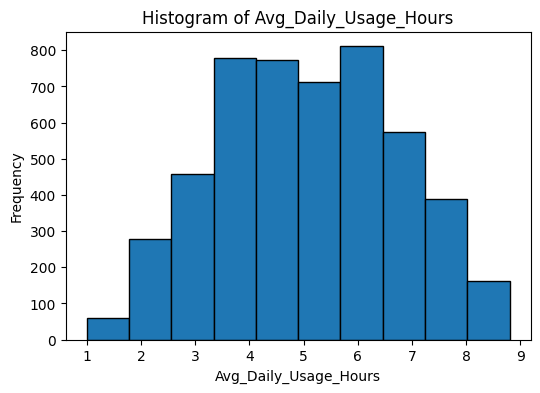

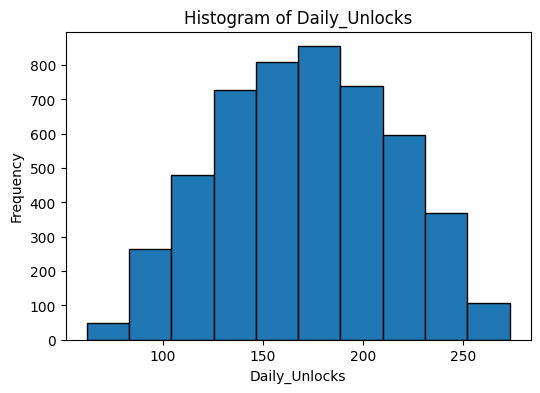

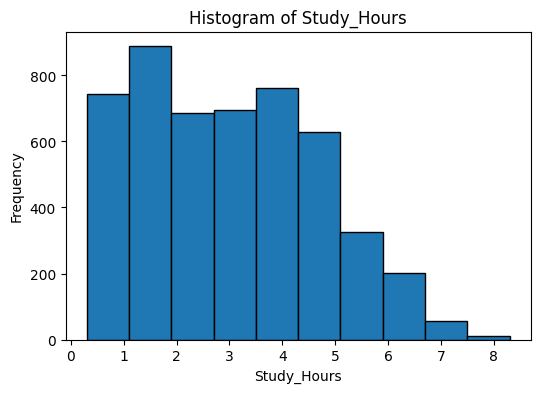

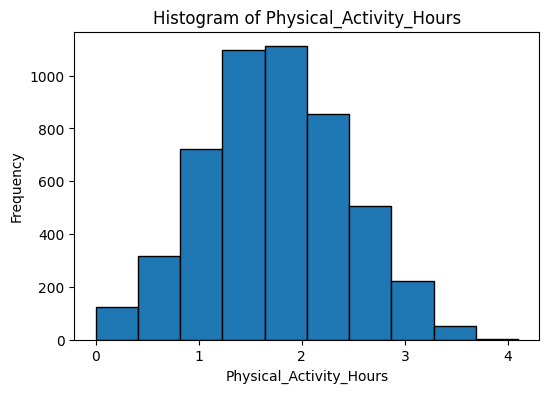

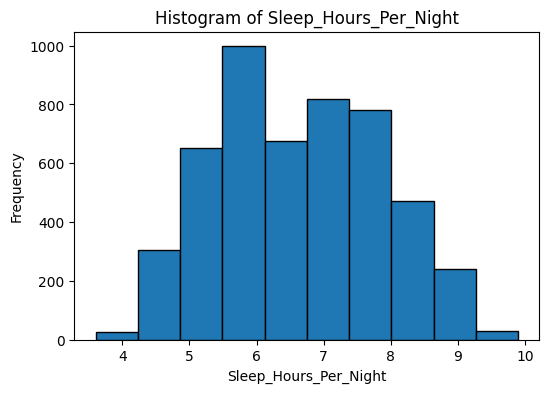

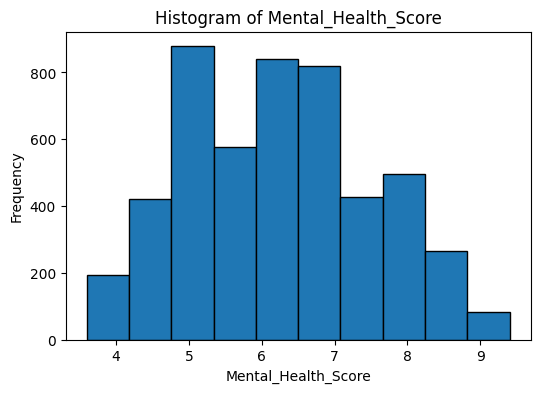

In [17]:
num_cols = [
    'Age',
    'Avg_Daily_Usage_Hours',
    'Daily_Unlocks',
    'Study_Hours',
    'Physical_Activity_Hours',
    'Sleep_Hours_Per_Night',
    'Mental_Health_Score'
]

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=10, edgecolor='black')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

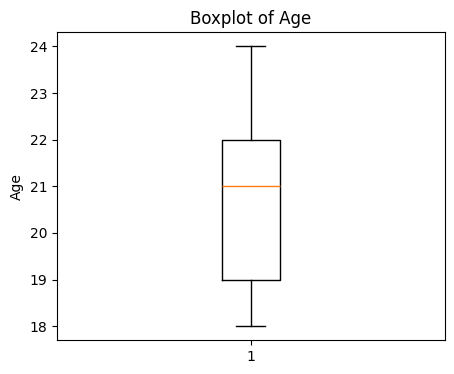

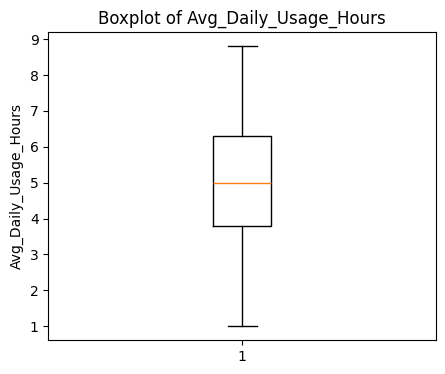

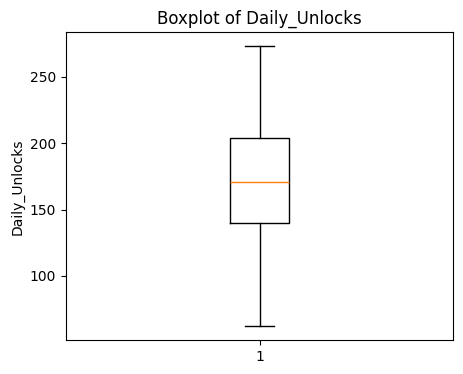

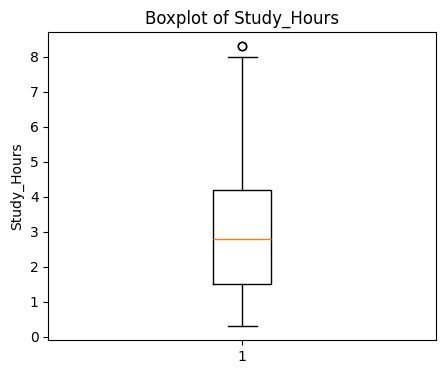

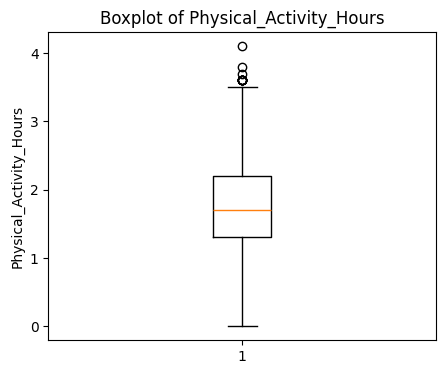

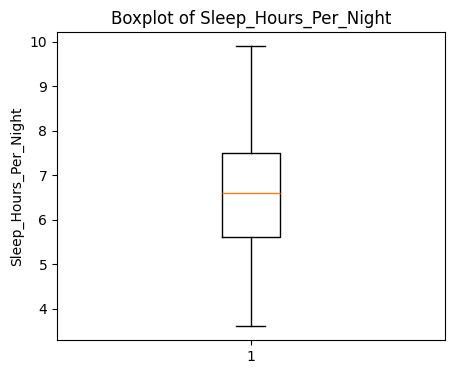

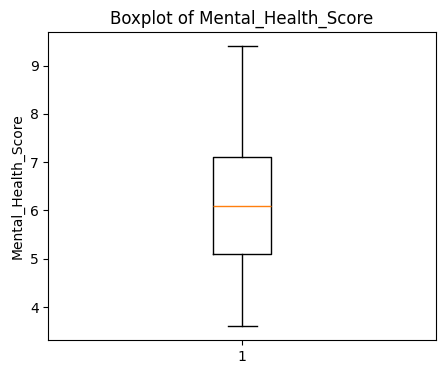

In [18]:
for col in num_cols:
    plt.figure(figsize=(5,4))
    plt.boxplot(df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)
    plt.show()

# Detect outliers for all numerical columns

In [19]:
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")

Age : 0 outliers
Avg_Daily_Usage_Hours : 0 outliers
Daily_Unlocks : 0 outliers
Study_Hours : 2 outliers
Physical_Activity_Hours : 12 outliers
Sleep_Hours_Per_Night : 0 outliers
Mental_Health_Score : 0 outliers


In [20]:
Q1 = df['Study_Hours'].quantile(0.25)
Q3 = df['Study_Hours'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df.loc[
    (df['Study_Hours'] < lower) | (df['Study_Hours'] > upper),
    'Study_Hours'
] = df['Study_Hours'].median()

In [21]:
Q1 = df['Physical_Activity_Hours'].quantile(0.25)
Q3 = df['Physical_Activity_Hours'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df.loc[
    (df['Physical_Activity_Hours'] < lower) | (df['Physical_Activity_Hours'] > upper),
    'Physical_Activity_Hours'
] = df['Physical_Activity_Hours'].median()

# Feature Scaling

In [22]:
scaler = StandardScaler()

num_cols = [
    'Age',
    'Avg_Daily_Usage_Hours',
    'Daily_Unlocks',
    'Study_Hours',
    'Physical_Activity_Hours',
    'Sleep_Hours_Per_Night',
    'Mental_Health_Score'
]

df[num_cols] = scaler.fit_transform(df[num_cols])


In [23]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,0.102425,Male,Other,Undergraduate,Facebook,Networking,-0.652077,-0.873996,0.914384,0.686794,0.053499,Medium,0.444986
1,1.254100,Female,Other,Graduate,LinkedIn,Education,-2.103165,-2.297383,2.445485,0.989599,1.609042,Low,1.070794
2,0.678263,Male,Canada,Undergraduate,Instagram,Entertainment,-0.289305,-0.127302,0.608164,0.081184,0.053499,Medium,0.601438
3,-1.625088,Male,Other,High School,Snapchat,Entertainment,1.161782,1.132745,-1.229157,-0.070218,-1.010819,Very High,-0.728403
4,1.829938,Female,Other,Graduate,Facebook,Networking,1.464092,1.529427,-1.229157,-0.978633,-1.338302,Very High,-1.432437


# Encoding techniques

In [24]:
le = LabelEncoder()

df['Academic_Level'] = le.fit_transform(df['Academic_Level'])
df['Stress_Level'] = le.fit_transform(df['Stress_Level'])


In [25]:
df = pd.get_dummies(
    df,
    columns=[
        'Gender',
        'Country',
        'Most_Used_Platform',
        'Purpose_Of_Use'
    ],
    drop_first=False
)


In [26]:
df.head()

,Age,Academic_Level,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Gender_Female,...,Most_Used_Platform_TikTok,Most_Used_Platform_Twitter,Most_Used_Platform_VKontakte,Most_Used_Platform_WeChat,Most_Used_Platform_WhatsApp,Most_Used_Platform_YouTube,Purpose_Of_Use_Education,Purpose_Of_Use_Entertainment,Purpose_Of_Use_Networking,Purpose_Of_Use_News
0,0.102425,2,-0.652077,-0.873996,0.914384,0.686794,0.053499,2,0.444986,False,...,False,False,False,False,False,False,False,False,True,False
1,1.254100,0,-2.103165,-2.297383,2.445485,0.989599,1.609042,1,1.070794,True,...,False,False,False,False,False,False,True,False,False,False
2,0.678263,2,-0.289305,-0.127302,0.608164,0.081184,0.053499,2,0.601438,False,...,False,False,False,False,False,False,False,True,False,False
3,-1.625088,1,1.161782,1.132745,-1.229157,-0.070218,-1.010819,3,-0.728403,False,...,False,False,False,False,False,False,False,True,False,False
4,1.829938,0,1.464092,1.529427,-1.229157,-0.978633,-1.338302,3,-1.432437,True,...,False,False,False,False,False,False,False,False,True,False


# Split the dataset into training and testing sets

In [2]:
X = df.drop(columns=['Mental_Health_Score'])
y = df['Mental_Health_Score']


NameError: name 'df' is not defined

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [29]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (3998, 137)
X_test shape : (1000, 137)
y_train shape: (3998,)
y_test shape : (1000,)
